In [90]:
import numpy as np
import scipy as sp
import CoolProp.CoolProp as CP
import thermo as thermo
import matplotlib.pyplot as plt

define vapor pressure and diffusion functions

In [91]:
def vapor_pressure_graphite(T):
    """
    Returns the vapor pressure of graphite as a function of temperature T (in Kelvin).
    "The Vapor Pressure and Heat of Sublimation of Graphite" - Brewer et al
    """
    # Example implementation (replace with actual formula)
    return 10 ** (8.02 - 37170 / T) * 101000
    #return 10 ** (9.93 - 40158 / T) * 101000

def vapor_pressure_zrc(T):
    """
    Returns the vapor pressure of ZrC as a function of temperature T (in Kelvin).
    "THE VAPORIZATION BEHAVIOR AND THERMODYNAMIC STABILITY OF
    ZIRCONIUM CARBIDE AT HIGH TEMPERATURE" - Pollock
    """
    # Example implementation (replace with actual formula)
    return 10 ** (8.3846 - 43875 / T) * 101000
    #return 10 ** (7.3846 - 43875 / T) * 101000 #est for TaC
    #return 10 ** (8.85 - 40524 / T) * 101000

def vapor_pressure_tac(T):
    """
    Returns the vapor pressure of ZrC as a function of temperature T (in Kelvin).
    "THE VAPORIZATION BEHAVIOR AND THERMODYNAMIC STABILITY OF
    ZIRCONIUM CARBIDE AT HIGH TEMPERATURE" - Pollock
    """
    # Est as 0.1x the vapor pressure of ZrC
    return 10 ** (7.3846 - 43875 / T) * 101000
    #return 10 ** (8.85 - 40524 / T) * 101000

def vapor_pressure_tungsten(T):
    """
    Returns the vapor pressure of tungsten as a function of temperature T (in Kelvin).
        "Vapor Pressure and Heat of Sublimation of Tungsten" - Plante and Sessoms
    """
    # Example implementation (replace with actual formula)
    return 10 ** (7.781 - 45385 / T) * 101000

def diffusion_coefficient_carbon_zrc(T):
    """
    Returns the diffusion coefficient of carbon through ZrC as a function of temperature T (in Kelvin).
    """
    # Example implementation (replace with actual formula)
    #return 1.6e-4 * np.exp(-90000 / (8.314 * T))
    return 1.32e-2 * np.exp(-56970 / (T))
    #return 2e-4 * np.exp(-45650/T) #est for TaC
    #return 8.3e-7 * np.exp(9.2 * .214 - 36000 / T)

def diffusion_coefficient_carbon_tac(T):
    """
    Returns the diffusion coefficient of carbon through ZrC as a function of temperature T (in Kelvin).
    """
    # Example implementation (replace with actual formula)
    #return 1.6e-4 * np.exp(-90000 / (8.314 * T))
    #return 1.32e-2 * np.exp(-56970 / (T))
    return 2e-4 * np.exp(-45650/T)

def diffusion_coefficient_carbon_tungsten(T):
    """
    Returns the diffusion coefficient of carbon through tungsten as a function of temperature T (in Kelvin).
    """
    # Example implementation (replace with actual formula)
    return 9.22e-7 * np.exp(-169805 / (8.314 * T))

def diffusion_coefficient_kinetic_theory(T_emitter, M_species, M_argon=39.95, P_total=101325):
    """
    Calculate diffusion coefficient of a species through argon using kinetic theory.
    
    Based on kinetic theory for dilute gas mixtures.
    
    Parameters:
    -----------
    T_emitter : float
        Temperature of the argon gas (K)
    M_species : float
        Molar mass of the species (g/mol) - carbon (12) or tungsten (183.84)
    M_argon : float
        Molar mass of argon (g/mol), default = 39.95
    P_total : float
        Total pressure (Pa), default = 101325 Pa (1 atm)
    
    Returns:
    --------
    float
        Diffusion coefficient (m²/s)
    
    Notes:
    ------
    Skelland equation for binary gas diffusion (using reduced mass form):
    D_AB = (0.00186 * T^1.5) / (P * sigma_AB^2) * sqrt(1/M_A + 1/M_B) * Omega_D
    
    where:
    - T is temperature in K
    - M_A, M_B are molar masses in g/mol
    - P is pressure in atm
    - sigma_AB is collision diameter in Ångströms
    - Omega_D is collision integral (~1.0 for most cases)
    - Result is in cm²/s, converted to m²/s by multiplying by 1e-4
    """
    # Estimate collision diameter in Ångströms
    # Using rough estimates: argon ~3.6 Å, carbon atom ~3.0 Å, tungsten ~3.5 Å
    if M_species < 50:  # Carbon
        sigma_A = 3.0  # Ångströms
    else:  # Tungsten
        sigma_A = 3.5  # Ångströms
    sigma_argon = 3.6  # Ångströms
    sigma_AB = (sigma_A + sigma_argon) / 2  # Mixing rule (Ångströms)
    
    # Collision integral (approximately 1.0 for most temperature ranges)
    Omega_D = 1.0
    
    # Convert pressure from Pa to atm
    P_atm = P_total / 101325
    
    # Skelland equation with reduced mass formulation
    D_diffusive = 0.00186 * T_emitter ** 1.5 / (P_atm * sigma_AB ** 2 * Omega_D) * np.sqrt(1 / M_species + 1 / M_argon) / 1e4
    
    return D_diffusive

def convective_mass_transfer_coefficient_buoyancy(T_emitter, T_cold, L_characteristic=0.1, 
                                                   g=9.81, M_species=12, M_argon=39.95):
    """
    Estimate convective mass transfer coefficient due to buoyancy-driven flow.
    
    Based on natural convection correlations and boundary layer theory.
    
    Parameters:
    -----------
    T_emitter : float
        Hot surface temperature (K)
    T_cold : float
        Cold reference temperature (K)
    L_characteristic : float
        Characteristic length scale (m), default = 0.1 m
    g : float
        Gravitational acceleration (m/s²), default = 9.81
    M_species : float
        Molar mass of the species (g/mol)
    M_argon : float
        Molar mass of argon (g/mol)
    
    Returns:
    --------
    float
        Convective mass transfer coefficient (m/s)
    
    Notes:
    ------
    Natural convection is driven by buoyancy due to density differences from:
    1. Temperature gradients
    2. Concentration gradients of evaporating species
    
    For vertical surfaces with natural convection:
    Sh = 0.59 * Gr_m^(1/4)  (laminar, Gr_m < 10^9)
    Sh = 0.13 * Gr_m^(1/3)  (turbulent, Gr_m > 10^9)
    
    Gr_m = g * beta_m * Delta_rho * L^3 / mu^2
    Sh = h_m * L / D
    """
    
    # Mean temperature for properties
    T_mean = (T_emitter + T_cold) / 2
    
    # Argon properties at mean temperature (simplified)
    # Dynamic viscosity (Pa·s) - rough approximation
    mu = 2.1e-5 * (T_mean / 300) ** 0.7
    
    # Density using ideal gas law: rho = PM/RT
    R = 8.314  # J/(mol·K)
    M_argon_kg = M_argon / 1000  # kg/mol
    rho_mean = 101325 * M_argon_kg / (R * T_mean)  # kg/m³
    
    # Thermal expansion coefficient (for ideal gas): beta = 1/T
    beta_T = 1.0 / T_mean
    
    # Density difference due to temperature variation (approximate)
    Delta_rho_temp = rho_mean * beta_T * (T_emitter - T_cold)
    
    # Additional density difference due to molar mass difference between evaporating species and argon
    # This is a concentration effect - lighter species rise, heavier species sink
    mass_difference_factor = abs(M_species - M_argon) / M_argon
    Delta_rho_mass = rho_mean * 0.01 * mass_difference_factor  # Estimate ~1% concentration change
    
    # Total buoyancy-driven density difference
    Delta_rho_total = Delta_rho_temp + Delta_rho_mass
    
    # Grashof number (modified for mass transfer - Gr_m)
    Gr_m = g * Delta_rho_total * L_characteristic**3 / (rho_mean * mu**2)
    
    # Get diffusion coefficient for Sherwood number calculation
    D_species_argon = diffusion_coefficient_kinetic_theory(T_mean, M_species, M_argon)
    
    # Sherwood number correlation (natural convection)
    if Gr_m < 1e9:
        # Laminar natural convection
        Sh = 0.59 * Gr_m ** 0.25
    else:
        # Turbulent natural convection
        Sh = 0.13 * Gr_m ** (1/3)
    
    # Convert Sherwood to mass transfer coefficient
    # Sh = h_m * L / D  =>  h_m = Sh * D / L
    h_m = Sh * D_species_argon / L_characteristic
    
    return h_m

def mass_transfer_coefficient_combined(T_emitter, T_cold, L_characteristic=0.1, M_species=12):
    """
    Calculate combined mass transfer coefficient including both diffusive and convective contributions.
    
    Parameters:
    -----------
    T_emitter : float
        Hot surface temperature (K)
    T_cold : float
        Cold reference temperature (K)
    L_characteristic : float
        Characteristic length scale (m)
    M_species : float
        Molar mass of the species (g/mol) - carbon (12) or tungsten (183.84)
    
    Returns:
    --------
    dict
        Dictionary containing:
        - 'h_m_diffusive': Diffusive mass transfer coefficient (m/s)
        - 'h_m_convective': Convective mass transfer coefficient (m/s)
        - 'h_m_total': Combined mass transfer coefficient (m/s)
        - 'Sh_number': Sherwood number
        - 'Gr_m_number': Grashof number (modified for mass transfer)
        - 'D_kinetic': Diffusion coefficient from kinetic theory (m²/s)
    """
    
    T_mean = (T_emitter + T_cold) / 2
    
    # Get kinetic theory diffusion coefficient
    D_kinetic = diffusion_coefficient_kinetic_theory(T_mean, M_species)
    
    # Diffusive contribution: h_m,diff = D / L
    h_m_diffusive = D_kinetic / L_characteristic
    
    # Convective contribution: h_m,conv from buoyancy-driven flow
    h_m_convective = convective_mass_transfer_coefficient_buoyancy(T_emitter, T_cold, 
                                                                   L_characteristic, M_species=M_species)
    
    # Combined: use sum approach (assumes independence, valid when both mechanisms active)
    h_m_total = h_m_diffusive + h_m_convective
    
    # Calculate Grashof for reference
    mu = 2.1e-5 * (T_mean / 300) ** 0.7
    R = 8.314
    M_argon_kg = 39.95 / 1000
    rho_mean = 101325 * M_argon_kg / (R * T_mean)
    beta_T = 1.0 / T_mean
    Delta_rho_temp = rho_mean * beta_T * (T_emitter - T_cold)
    mass_difference_factor = abs(M_species - 39.95) / 39.95
    Delta_rho_mass = rho_mean * 0.01 * mass_difference_factor
    Delta_rho_total = Delta_rho_temp + Delta_rho_mass
    Gr_m = 9.81 * Delta_rho_total * L_characteristic**3 / (rho_mean * mu**2)
    
    # Sherwood number
    if Gr_m < 1e9:
        Sh = 0.59 * Gr_m ** 0.25
    else:
        Sh = 0.13 * Gr_m ** (1/3)
    
    return {
        'h_m_diffusive': h_m_diffusive,
        'h_m_convective': h_m_convective,
        'h_m_total': h_m_total,
        'Sh_number': Sh,
        'Gr_m_number': Gr_m,
        'D_kinetic': D_kinetic
    }

def diffusion_coefficient_carbon_argon(T, diff_or_conv_bool):
    """
    Returns the diffusion coefficient of carbon in argon as a function of temperature T (in Kelvin).
    """
    # Example implementation (replace with actual formula)
    if diff_or_conv_bool:
        return 1e-5 * (T / 298) ** 1.75  # m²/s (estimate for static gas, used for propgation through cracks because very low Re, dP)
    else:
        return 7e-2 # m²/s (estimate for mixed gas with turbulence, assumed because of gas curtains and temp variations)
    
def diffusion_coefficient_tungsten_argon(T, diff_or_conv_bool):
    """
    Returns the diffusion coefficient of carbon in argon as a function of temperature T (in Kelvin).
    """
    # Example implementation (replace with actual formula)
    if diff_or_conv_bool:
        return 1e-6 * (T / 298) ** 1.75  # m²/s (estimate for static gas, used for propgation through cracks because very low Re, dP)
    else:
        return 7e-3 # m²/s (estimate for mixed gas with turbulence, assumed because of gas curtains and temp variations)

def diffusion_flux(D, C1, C2, L):
    """
    Calculate the diffusion flux of carbon through a medium.

    Parameters:
    D (float): Diffusion coefficient (m²/s).
    C1 (float): Concentration of carbon at one boundary (mol/m³).
    C2 (float): Concentration of carbon at the other boundary (mol/m³).
    L (float): Thickness of the medium (m).

    Returns:
    float: Diffusion flux of carbon through the medium (mol/m²·s).
    """
    return -D * (C2 - C1) / L

Material thermal properties

In [92]:
def Sn_rho(temp):
    #return liquid Tin density, Stankus
    return 5623
    #return 6982.2 - 0.75643 * (temp - 505) + 1.074e-4 * (temp - 505) ** 2 - 2.194e-8 * (temp - 505) ** 3

def Sn_tcx(temp):
    #return liquid Tin thermal conductivity [W/mK] fix this one?
    return 90.56
    #return 13.9 * 0.02868 * temp

def Sn_mu(temp):
    #return liquid Tin viscosity [Pas]
    return 0.000525
    #return 3.908e-4 * np.exp(790.7 / temp)

def Sn_cp(temp):
    #return liquid Tin cp [J/kgK]
    return 300
    #return 182.7 + 0.05177 * temp + 1.086e7 * temp ** (-2)

def Sn_Pr (temp):
    #return Prandtl number
    return Sn_cp(temp) * Sn_mu(temp)  / Sn_tcx(temp)

def gr_rho(temp: float) -> float:
    return 1743
    
def gr_tcx(temp: float) -> float:
    """
    Calculate the thermal conductivity of graphite as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Thermal conductivity of graphite (W/mK).
    """
    tcx_arr = np.array([[20,	115],
    [200,	100],
    [400,	85],
    [600,	73],
    [800,	62],
    [1000,	54],
    [1200,	49],
    [1400,	45],
    [1600,	42],
    [1800,	40],
    [2000,	39],
    [2200,	37],
    [2400,	34]]
    )
    return 51.5
    #return np.interp(1100,tcx_arr[:,0],tcx_arr[:,1])

def w_tcx(temp: float) -> float:
    """
    Calculate the thermal conductivity of tungsten as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Thermal conductivity of tungsten (W/mK).
    """
    # Example function for tungsten thermal conductivity; adjust this based on actual data.
    if temp < 300:
        return 173
    elif temp < 1000:
        return 173 - 0.03 * (temp - 300)
    else:
        return 152 - 0.01 * (temp - 1000)

def gr_emis(temp: float) -> float:
    """
    Calculate the emissivity of graphite as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Emissivity of graphite.
    """
    return 0.8
    #return 0.679 + 6e-5 * temp

def w_emis(temp: float) -> float:
    """
    Calculate the emissivity of tungsten as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Emissivity of tungsten.
    """
    # Example function for tungsten emissivity; adjust this based on actual data.
    return 0.3 - 1e-5 * temp

def zrc_emis(temp: float) -> float:
    """
    Calculate the emissivity of zrc as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Emissivity of zrc.
    """
    return 0.6

def tac_emis(temp: float) -> float:
    """
    Calculate the emissivity of zrc as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Emissivity of zrc.
    """
    return 0.6

def w_emis_spectral(temp: float, wavelength: float, bandgap: float) -> float:

    if wavelength < bandgap:
        return 0.4126
    else:
        return 0.2748

def gr_rho_molar(temp: float) -> float:
    return 55000.0

def zrc_rho_molar(temp: float) -> float:
    return 64020.0

def w_rho_molar(temp: float) -> float:
    return 105263.0

def RCondWall(L, A_c, k_wall):
    #define planar conduction thermal resistance [K/W]
    return L / (k_wall * A_c)

def RConvWall(Nu, L, A_c, k_fluid):
    #def convection thermal resistance on a planar wall [K/W]
    #L is the characteristic length, hydraulic diameter for internal flows
    h_bar = Nu * k_fluid / L
    return 1 / (h_bar * A_c)

def Rrad(T_sur, T_s, A_s, VF, emis):
    #def exact radiation thermal resistance [K/W]
    return 1 / (A_s * emis * (T_s ** 2 + T_sur ** 2) * (T_sur + T_s) * sp.constants.sigma)

def Rrad_2surfaces(T_1, T_2, A_1, A_2, emis_1, emis_2, VF_12):
    #def radiation thermal resistance between 2 grey bodies [K/W]
    R_rad = ((1 - emis_1) / (A_1 * emis_1) + 1 / (A_1 * VF_12) + (1 - emis_2) / 
             (A_2 * emis_2)) / ((T_1 ** 2 + T_2 ** 2) * (T_1 + T_2) * sp.constants.sigma)
    return R_rad

def RectPipeFF(Re, H, W, rough):
    #return recatngular pipe friction factor from Nellis and Klein, eq 5-60 and 5-65
    AR = H / W
    D_h = 2 * H * W / (H + W)
    if (Re < 2300):
        return 96 / Re * (1 - 1.3553 * AR + 1.9467 * AR ** 2 - 1.7012 * AR ** 3 + 0.9564 * AR ** 4 - 0.2537 * AR ** 5)
    else:
        return (-2 * np.log10(2 * rough / (7.54 * D_h) - 5.02 / Re * np.log10(2 * rough / (7.54 * D_h) + 13 / Re))) ** (-2)

def RectPipeNu(Re, H, W, ff, Pr):
    #return rectangular pipe Nusselt number
    AR = H / W
    if (Re < 2300):
        return 8.235 * (1 - 2.042 * AR + 3.085 * AR ** 2 -2.477 * AR ** 3 + 1.058 * AR ** 4 - 0.186 * AR ** 5)
    else:
        return (ff / 8 * (Re - 1000) * Pr) / (1 + 12.7 * (Pr ** 0.667 - 1) * np.sqrt(ff / 8))

Power Block functions from system modelling

In [93]:
class RectangularPipe:
    def __init__(self, H: float, W: float, length: float, roughness: float):
        """
        Initialize the RectangularPipe object with its physical properties.
        
        Parameters:
        H (float): Height of the rectangular pipe (m).
        W (float): Width of the rectangular pipe (m).
        length (float): Length of the pipe (m).
        roughness (float): Roughness of the pipe (m).
        """
        self.H = H
        self.W = W
        self.length = length
        self.roughness = roughness
        self.D_h = 2 * H * W / (H + W)
        self.A_s = 2 * (H + W) * length

class Fluid:
    def __init__(self, temperature: float, pressure: float, flow_rate: float):
        """
        Initialize the Fluid object with its properties.
        
        Parameters:
        temperature (float): Temperature of the fluid (K).
        pressure (float): Pressure of the fluid (Pa).
        flow_rate (float): Flow rate of the fluid (kg/s).
        """
        self.temperature = temperature
        self.pressure = pressure
        self.flow_rate = flow_rate

class PowerStick:
    def __init__(self, axial_steps: int, width: float, height: float, cooling_temp: float, panel_efficiency: float,  f_bare: float, f_active: float, emissivity_table: list = None):
        """
        Initialize the PowerStick object with its physical properties.
        
        Parameters:
        width (float): Width of the power stick (m).
        height (float): Height of the power stick (m).
        cooling_temp (float): Cooling temperature to maintain the power stick (K).
        panel_efficiency (float): Percent of absorbed light above bandgap converted to electricity
        emissivity_table (list): List of tuples containing wavelength ranges and corresponding emissivities.
        """
        self.num_ax_steps = axial_steps
        self.width = width
        self.height = height
        self.height_step = self.height / self.num_ax_steps
        self.A_step = 4 * self.height_step * self.width 
        self.cooling_temp = cooling_temp
        self.emissivity_table = emissivity_table if emissivity_table is not None else []
        self.panel_efficiency = panel_efficiency
        self.f_bare = f_bare
        self.f_active = f_active

    def update_emissivity_table(self, new_emissivity_table):
        self.emissivity_table = new_emissivity_table

    def generate_electricity_step_no_GD(self, T_emitter: float, emitter_emissivity: float, view_factor: float, efficiency: float) -> tuple:
        """
        Calculate the electricity generated by the power stick based on incident energy.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        efficiency (float): Efficiency of converting absorbed heat to electricity.
        
        Returns:
        tuple: Electricity generated (W) and waste heat to be removed by the cooling system (W).
        """
        #incident_energy_bins, emissivity_bins = self.incident_energy_one_W_bin(T_emitter, emitter_emissivity, view_factor)
        incident_energy_bins, emissivity_bins = self.incident_energy(T_emitter, view_factor)
        absorbed_energy_below_bandgap = 0
        absorbed_energy_above_bandgap = 0
        
        for i, (wavelength_range, emissivity) in enumerate(self.emissivity_table):
            if i == 0:  # First bin is below the bandgap
                absorbed_energy_below_bandgap += incident_energy_bins[wavelength_range] * emissivity
            elif i == 1:  # Second bin is above the bandgap
                absorbed_energy_above_bandgap += incident_energy_bins[wavelength_range] * emissivity

        total_absorbed_energy = absorbed_energy_below_bandgap + absorbed_energy_above_bandgap
        absorbed_heat = total_absorbed_energy * self.A_step  # Total absorbed heat (W)
        electricity = absorbed_energy_below_bandgap * self.A_step * efficiency
        waste_heat = absorbed_heat - electricity
        return electricity, waste_heat

    def generate_electricity_step(self, T_emitter: float, view_factor: float, efficiency: float, th_liner: float, th_zrc: float) -> tuple:
        """
        Calculate the electricity generated by the power stick based on incident energy.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        efficiency (float): Efficiency of converting absorbed heat to electricity.
        
        Returns:
        tuple: Electricity generated (W) and waste heat to be removed by the cooling system (W).
        """
        incident_energy_bins, emissivity_bins, incident_photon_bins = self.incident_energy(T_emitter, view_factor, th_liner, th_zrc)
        #print(incident_energy_bins, emissivity_bins)
        absorbed_energy_below_bandgap = 0
        absorbed_energy_above_bandgap = 0
        absorbed_energy_bare = 0
        absorbed_energy_inactive = 0
        #elec_flux = 0
        #e_charge = 1.60218e-19 #electron charge, Coulombs
        #P_collect = 1 #probability of photon above bandgap being absorbed
        #V_panel = 1 #voltage on panel, update
        #N_bounces = 5
        for i, (wavelength_range, emis_active, emis_bare, emis_inactive) in enumerate(self.emissivity_table):
            avg_panel_emis = self.f_bare * emis_bare + (1 - self.f_bare) * self.f_active * emis_active + (1 - self.f_bare) * (1- self.f_active) * emis_inactive
            #print("abs energy: ",wavelength_range,incident_energy_bins[wavelength_range] * self.A_step * (1 - self.f_bare) * self.f_active)
            #for j in range(N_bounces):
            if th_liner == 0: #no liner
                if th_zrc == 0: #no coating
                    emitter_emis = gr_emis(T_emitter)
                else:
                    emitter_emis = zrc_emis(T_emitter)
            else:
                emitter_emis = w_emis_spectral(T_emitter, (wavelength_range[0] + wavelength_range[0]) / 2, 1)
            absorbed_energy_bare += incident_energy_bins[wavelength_range] * self.f_bare * emis_bare  / avg_panel_emis
            absorbed_energy_inactive += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * (1 - self.f_active) * emis_inactive / avg_panel_emis
            if i == 0:  # First bin is below the bandgap
                absorbed_energy_below_bandgap += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * self.f_active * emis_active / avg_panel_emis
                #elec_flux += incident_photon_bins[wavelength_range] * emis_active * P_collect * e_charge * V_panel
            elif i == 1:  # Second bin is above the bandgap
                absorbed_energy_above_bandgap += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * self.f_active * emis_active / avg_panel_emis
            #determine amount of reflected light in bin that will bounce back to stick
                #print("band, e_inc, abs_bare, abs_inac, abs_below, abs_above:",wavelength_range, incident_energy_bins[wavelength_range], absorbed_energy_bare, absorbed_energy_inactive, absorbed_energy_below_bandgap, absorbed_energy_above_bandgap)
                #incident_energy_bins[wavelength_range] *= (1 - (emis_bare * self.f_bare + emis_inactive * (1 - self.f_bare) * (1 - self.f_active)
                #                                        + emis_active * (1 - self.f_bare) * self.f_active)) * view_factor * (1 - emitter_emis)
                

        absorbed_heat = (absorbed_energy_below_bandgap + absorbed_energy_above_bandgap + absorbed_energy_bare + absorbed_energy_inactive) * self.A_step  # Total absorbed heat (W)
        electricity = absorbed_energy_below_bandgap * self.A_step# * efficiency
        #electricity2 = elec_flux * self.A_step
        waste_heat = absorbed_heat - electricity
        #print(absorbed_energy_below_bandgap, absorbed_energy_above_bandgap, absorbed_energy_bare, absorbed_energy_inactive, self.A_step)
        return electricity, waste_heat

    def incident_energy_one_W_bin(self, T_emitter: float, emitter_emissivity: float, view_factor: float) -> tuple:
        """
        Calculate the total amount of incident energy on the powerstick surface in each energy bin based on the blackbody spectrum.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        
        Returns:
        tuple: Total amount of incident energy in each energy bin (W/m^2), and corresponding powerstick emissivities.
        """
        # Constants
        h = 6.62607015e-34  # Planck constant (J·s)
        c = 2.99792458e8    # Speed of light (m/s)
        k = 1.380649e-23    # Boltzmann constant (J/K)
        
        # Initialize dictionaries to store incident energy and powerstick emissivity for each bin
        incident_energy_bins = {range_: 0.0 for range_, _ in self.emissivity_table}
        emissivity_bins = {range_: emissivity for range_, emissivity in self.emissivity_table}
        
        # Wavelength range (microns)
        wavelengths = np.linspace(0.1, 25, 1000)  # Example wavelength range from 0.01 to 10 microns
        wavelengths_m = wavelengths * 1e-6  # Convert to meters
        
        # Planck's law (Watts / square meter / meter)
        spectral_radiance = np.pi * (2 * h * c**2) / (wavelengths_m**5) * (1 / (np.expm1((h * c) / (wavelengths_m * k * T_emitter))))
        
        # Calculate incident energy
        for i, wavelength in enumerate(wavelengths):
            for (wavelength_range, panel_emissivity) in self.emissivity_table:
                if wavelength_range[0] <= wavelength < wavelength_range[1]:
                    incident_energy_bins[tuple(wavelength_range)] += (
                        spectral_radiance[i] * (wavelengths_m[1] - wavelengths_m[0]) / (view_factor * 
                                    (1 - emitter_emissivity) / emitter_emissivity + 1 + (1 - panel_emissivity) / panel_emissivity)
                    )
                    break

        return incident_energy_bins, emissivity_bins

    def incident_energy(self, T_emitter: float, view_factor: float, th_liner: float, th_zrc: float) -> tuple:
        """
        Calculate the total amount of incident energy on the powerstick surface in each energy bin based on the blackbody spectrum.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        
        Returns:
        tuple: Total amount of incident energy in each energy bin (W/m^2), and corresponding powerstick emissivities.
        """
        # Constants
        h = 6.62607015e-34  # Planck constant (J·s)
        c = 2.99792458e8    # Speed of light (m/s)
        k = 1.380649e-23    # Boltzmann constant (J/K)
        
        # Initialize dictionaries to store incident energy and powerstick emissivity for each bin
        incident_energy_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        incident_photon_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        raw_rad_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        emissivity_bins = {range_: emissivity for range_, emissivity, _, _ in self.emissivity_table}
        
        # Wavelength range (microns)
        wavelength_min = self.emissivity_table[0][0][0]
        wavelength_max = self.emissivity_table[1][0][1]
        band_gap = self.emissivity_table[0][0][1]
        n_bins = 500
        
        #wavelengths = np.concatenate((np.linspace(wavelength_min,band_gap,n_bins_0),np.linspace(band_gap + d_lambda_1, wavelength_max,n_bins_1)))
        wavelengths = np.logspace(np.log10(wavelength_min),np.log10(wavelength_max), n_bins)
        wavelengths_m = wavelengths * 1e-6  # Convert to meters
        # Planck's law (Watts / square meter / meter)
        spectral_radiance = np.pi * (2 * h * c**2) / (wavelengths_m**5) * (1 / (np.expm1((h * c) / (wavelengths_m * k * T_emitter))))
        spectral_count = spectral_radiance / (h * c / wavelengths_m)
        
        # Calculate incident energy
        for i, wavelength in enumerate(wavelengths):
            if th_liner == 0: #no liner
                if th_zrc ==0: #no coating
                    emitter_emis = gr_emis(T_emitter)
                else:
                    emitter_emis = zrc_emis(T_emitter)
            else:
                emitter_emis = w_emis_spectral(T_emitter, wavelength, band_gap)

            if wavelength < band_gap:
                #band_width = d_lambda_0 * 1e-6
                band_width = wavelengths_m[i+1] - wavelengths_m[i]
            else:
                #band_width = d_lambda_1 * 1e-6
                band_width = wavelengths_m[i] - wavelengths_m[i-1]
                
            for (wavelength_range, emis_active, emis_bare, emis_inactive) in self.emissivity_table:
                if wavelength_range[0] <= wavelength < wavelength_range[1]:
                    avg_panel_emis = self.f_bare * emis_bare + (1 - self.f_bare) * self.f_active * emis_active + (1 - self.f_bare) * (1- self.f_active) * emis_inactive
                    #raw_rad_bins[tuple(wavelength_range)] += spectral_radiance[i] * (band_width) * emitter_emis
                    incident_energy_bins[tuple(wavelength_range)] += (
                        spectral_radiance[i] * (band_width) / (view_factor * 
                                    (1 - emitter_emis) / emitter_emis + 1 + (1 - avg_panel_emis) / avg_panel_emis)
                    )
                    #print(wavelength,avg_panel_emis, emitter_emis,incident_energy_bins[tuple(wavelength_range)])
                    
                    incident_photon_bins[tuple(wavelength_range)] += spectral_count[i]
                    break
        #print(raw_rad_bins, incident_energy_bins)
        return incident_energy_bins, emissivity_bins, incident_photon_bins

class Emitter:
    def __init__(self, width: float, height: float, wall_thickness: float, pipe: RectangularPipe):
        """
        Initialize the Emitter object with its physical properties.
        
        Parameters:
        width (float): Width of the emitter (m).
        height (float): Height of the emitter (m).
        wall_thickness (float): Thickness of the graphite wall (m).
        tungsten_thickness (float): Thickness of the tungsten liner (m).
        pipe (RectangularPipe): Rectangular pipe object liquid tin channels
        """
        self.width = width
        self.height = height
        self.wall_thickness = wall_thickness
        self.pipe = pipe

    def R_tin_to_tungsten(self, fluid: Fluid, T_graphite: float, T_tungsten: float):
        """
        Calculate thermal resistance per meter between liquid tin and tungsten liner for given guess values of the graphite and tin temperatures
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        T_graphite (float): Graphite surface temperature guess (K)
        T_tungsten (float): Tungsten liner temperature guess (K)
        """
        mdot = fluid.flow_rate
        T_tin = fluid.temperature
        A_emitter = 4 * self.width  #emitter area per meter length
        u = mdot / (4 * Sn_rho(T_tin) * self.pipe.W * self.pipe.H) #mdot is 1/4 total mdot b/c 4 rectangular channels per module
        Re = Sn_rho(T_tin) * u * self.pipe.D_h / Sn_mu(T_tin)
        ff_pipe = RectPipeFF(Re, self.pipe.H, self.pipe.W, self.pipe.roughness)
        Nu_pipe = RectPipeNu(Re, self.pipe.H, self.pipe.W, ff_pipe, Sn_Pr(T_tin))
        h_conv = Nu_pipe * Sn_tcx(T_tin) / self.pipe.D_h
        R_conv = 1 / (h_conv * A_emitter)
            
        # Conduction resistance across graphite wall
        R_cond_graphite = self.wall_thickness / (gr_tcx(T_graphite) * A_emitter)
        # Radiative resistance from graphite to tungsten
        R_rad_graphite_tungsten = Rrad_2surfaces(T_graphite, T_tungsten, A_emitter, A_emitter,
                                                     gr_emis(T_graphite), w_emis(T_tungsten), 1.0)
        R_tot = R_conv + R_cond_graphite + R_rad_graphite_tungsten
        return R_tot, R_conv, R_cond_graphite, R_rad_graphite_tungsten

        
class PowerConversionBlock:
    def __init__(self,axial_steps: int, N_cells: int,
                     height_pipe: float, width_emitter: float, length: float, roughness_pipe: float, width_powerstick: float,
                     wall_thickness: float, cooling_temp: float, panel_efficiency: float, f_bare: float, f_active: float, emissivity_table: list = None):
        """
        Initialize the PowerConversionBlock object with its physical properties and components.
        
        Parameters:
        axial_steps (int): number of axial discretizations
        N_cells (int): number of powerstick/emitter assemblies
        T_tin_in (float): Tin inlet temperature (K)
        mdot_tot (float): Total tin mass flowrate (kg/s)
        height_pipe (float): Height of the rectangular pipe (m).
        width_emitter (float): Width of the emitter (m).
        length (float): Length of the components (m).
        roughness_pipe (float): Roughness of the pipe (m).
        width_powerstick (float): Width of the power stick (m).
        wall_thickness (float): Thickness of the graphite wall (m).
        panel_efficiency (float): Panel conversion efficiency above bandgap
        cooling_temp (float): Cooling temperature to maintain the power stick (K).
        emissivity_table (list): List of tuples containing wavelength ranges and corresponding emissivities.
        """
        self.pipe = RectangularPipe(H=height_pipe, W=width_emitter, length=length, roughness=roughness_pipe)
        self.emitter = Emitter(width=width_emitter, height=height_pipe, wall_thickness=wall_thickness, pipe=self.pipe)
        self.powerstick = PowerStick(axial_steps=axial_steps, panel_efficiency=panel_efficiency, width=width_powerstick,
                                     height=length, cooling_temp=cooling_temp, f_bare=f_bare, f_active=f_active, emissivity_table=emissivity_table)
        self.num_ax_steps = axial_steps
        self.N_cells = N_cells
        self.step_length = self.powerstick.height / self.num_ax_steps
        self.VF = self.powerstick.width / self.emitter.width

    def calculate_temperatures(self, fluid: Fluid, T_guess: float, th_w, th_zrc, tol_TW: float = 1e-3, max_iter: int = 100):
        """
        Iteratively solve for the graphite and tungsten temperatures using guess and check method.
        
        Parameters:
        fluid: (Fluid): Fluid object containing the flow conditions.
        T_guess (float): Initial guess for the tungsten temperature (K).
        tol_TW (float): Tolerance for temperature convergence (K).
        max_iter (int): Maximum number of iterations.
        
        Returns:
        tuple: Converged temperatures of graphite wall and tungsten liner (K).
        """
        T_tin = fluid.temperature
        P_tin = fluid.pressure
        mdot = fluid.flow_rate
        T_graphite = T_tin
        T_tungsten = T_guess
        A_emitter = 4 * self.emitter.width * self.step_length# * self.N_cells
        A_module = self.powerstick.A_step# * self.N_cells
        if th_w == 0: #no liner case
            for _ in range(max_iter):
                # Convective resistance from tin to graphite wall
                R_total_tin_to_tungsten, R_conv, R_cond_graphite, R_rad_graphite_tungsten = tuple(x / self.step_length for x in 
                                                        self.emitter.R_tin_to_tungsten(fluid, T_graphite, T_tungsten))
                
                Q_tin_to_wall = (T_tin - T_graphite) / (R_conv + R_cond_graphite)
                
                #electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_graphite, gr_emis(T_graphite), self.VF, 
                #                                                                              self.powerstick.panel_efficiency)
                electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_graphite, self.VF, 
                                                                                              self.powerstick.panel_efficiency, th_w, th_zrc)
                #print("abs band 0: ",electricity_step / self.powerstick.panel_efficiency, "abs band 1: ",waste_heat_step - electricity_step * (1 - self.powerstick.panel_efficiency) / self.powerstick.panel_efficiency)
                Q_wall_to_powerstick = electricity_step + waste_heat_step
                R_wall_to_powerstick = (T_graphite - self.powerstick.cooling_temp) / Q_wall_to_powerstick
                #revisit thermal resistance calc
                # Update guess for graphite temperature
                T_graphite_new = T_graphite + (Q_tin_to_wall - Q_wall_to_powerstick) * (R_conv + R_cond_graphite)
                if abs(T_graphite_new - T_graphite) < tol_TW:
                    return 0.0, T_graphite_new, Q_wall_to_powerstick*self.N_cells, electricity_step*self.N_cells
                
                T_graphite = T_graphite_new
            
            raise RuntimeError("Failed to converge to a solution for temperatures.")

        else:
            for _ in range(max_iter):
                # Convective resistance from tin to graphite wall
                R_total_tin_to_tungsten, R_conv, R_cond_graphite, R_rad_graphite_tungsten = tuple(x / self.step_length for x in 
                                                        self.emitter.R_tin_to_tungsten(fluid, T_graphite, T_tungsten))
                
                Q_tin_to_tungsten = (T_tin - T_tungsten) / R_total_tin_to_tungsten
                
                #electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_tungsten, w_emis(T_tungsten), self.VF, 
                #                                                                              self.powerstick.panel_efficiency)
                electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_tungsten, self.VF, 
                                                                                              self.powerstick.panel_efficiency, th_w, th_zrc)
                Q_tungsten_to_powerstick = electricity_step + waste_heat_step
                #print("abs band 0: ", electricity_step / self.powerstick.panel_efficiency, "abs band 1: ", waste_heat_step - electricity_step * (1 - self.powerstick.panel_efficiency) / self.powerstick.panel_efficiency)
                R_tungsten_to_powerstick = (T_tungsten - self.powerstick.cooling_temp) / Q_tungsten_to_powerstick
                #revisit thermal resistance calc
                # Update guess for tungsten and graphite temperature
                T_tungsten_new = T_tungsten + (Q_tin_to_tungsten - Q_tungsten_to_powerstick) * R_total_tin_to_tungsten
                T_graphite_new = T_tin - Q_tin_to_tungsten * (R_cond_graphite + R_conv)
                #print(T_graphite_new, Q_tungsten_to_powerstick)
                if abs(T_tungsten_new - T_tungsten) < tol_TW:
                    return T_tungsten_new, T_graphite_new, Q_tungsten_to_powerstick*self.N_cells, electricity_step*self.N_cells
                
                T_tungsten = T_tungsten_new
                T_graphite = T_graphite_new
            
            raise RuntimeError("Failed to converge to a solution for temperatures.")
        
    def power_conversion(self, fluid: Fluid):
        """
        Perform the power conversion calculations by discretizing the block axially.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions for the full power conversion system.
        
        Returns:
        tuple: Arrays containing the temperatures, electricity generated, and waste heat for each step.
        """
        # Initialize arrays to store results
        T_tin_in = fluid.temperature
        mdot = fluid.flow_rate
        temperatures = np.zeros(self.num_ax_steps + 1)
        electricity_generated = 0
        waste_heat = 0
        Q_rad = np.zeros(self.num_ax_steps)
        
        # Set initial temperature
        temperatures[0] = T_tin_in
    
        # Discretize axially and perform calculations
        for i in range(self.num_ax_steps):
            # Calculate heat transfer from liquid tin to emitter
            T_tin = temperatures[i]
            T_guess = T_tin - 100  # Initial guess for tungsten temperature
            fluid_cell_loc = Fluid(T_tin, fluid.pressure, mdot / self.N_cells)
            T_tungsten, _ = self.calculate_temperatures(fluid_cell_loc, T_guess)
            electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_tungsten, w_emis(T_tungsten),
                                                                                     self.VF, self.powerstick.panel_efficiency)
            # Store results
            electricity_generated += electricity_step
            waste_heat += waste_heat_step
            Q_rad[i] = electricity_step + waste_heat_step

            delta_T_tin = -Q_rad[i] / (mdot / self.N_cells * Sn_cp(temperatures[i]))
            temperatures[i + 1] = T_tin + delta_T_tin

        #Multiply by number of cells. 
        electricity_generated *= self.N_cells
        waste_heat *=self.N_cells
        return temperatures, electricity_generated, waste_heat

    def determine_outlet_conditions(self, fluid: Fluid) -> Fluid:
        """
        Determine the outlet conditions of the power conversion block.

        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.

        Returns:
        Fluid: Fluid object containing the outlet conditions.
        """
        temperatures, _, _ = self.power_conversion(fluid)
        T_out = temperatures[-1]
        fluid_pipe = Fluid(fluid.temperature, fluid.pressure, fluid.flow_rate / self.N_cells / 4)
        dp = self.pipe.pressure_drop(fluid_pipe)
        P_out = fluid.pressure - dp
        return Fluid(T_out, P_out, fluid.flow_rate)




In [94]:
def surface_temperatures(T_tin, T_cold, th_gr, th_zrc, th_w, geom_vals, emissivity_table):
    """
    Calculate the thermal resistance and determine the surface temperatures of the graphite and liner.
    
    Parameters:
    T_tin (float): Tin temperature in Kelvin.
    T_cold (float): Powerstick surface temperature in Kelvin.
    power (float): Power in Watts.
    th_gr (float): Graphite layer thickness in meters.
    th_zrc (float): ZrC layer thickness in meters.
    th_w (float): Tungsten liner thickness in meters.
    
    Returns:
    float: Surface temperature in Kelvin.
    """
    #emissivity_table = [
    #    ((0.0, 1.0), 0.95, 0.05, 0.02),  # Below 1 micron
    #    ((1.0, 100), 0.05, 0.05, 0.02)  # Above 1 micron
    #]

    N_cells = geom_vals[6]
    P_tin_in = geom_vals[5] #Pa
    mdot = geom_vals[7]  # kg/s, arbitrarily high
    panel_efficiency = geom_vals[9]
    axial_steps = geom_vals[8]
    pipe_height = geom_vals[3]
    emitter_width = geom_vals[1]
    length = geom_vals[0]
    pipe_roughness= geom_vals[4]
    powerstick_width = geom_vals[2]
    f_bare = geom_vals[10]
    f_active = geom_vals[11]
    wall_thickness = th_gr + th_zrc
    fluid_PCB_in = Fluid(T_tin, P_tin_in, mdot)
    PCB1=PowerConversionBlock(axial_steps, N_cells, pipe_height, emitter_width, length, pipe_roughness, 
                              powerstick_width,wall_thickness, T_cold, panel_efficiency, f_bare, f_active, emissivity_table)
    T_w, T_surf, Q_rad, Q_abs = PCB1.calculate_temperatures(fluid_PCB_in, T_tin, th_w, th_zrc)
    return T_w, T_surf, Q_rad, Q_abs
        

In [95]:
def deposition_rate(T_tin, T_cold, th_gr, th_w, th_coating, d, area_ratio_dep, area_ratio_leak, geom_vals, emis_table, diff_or_conv_bool, coating_type='ZrC'):
    """
    Calculate the deposition rate of carbon on the cold plate.

    Parameters:
    T_tin (float): Temperature of the tin (K).
    T_cold (float): Temperature of the cold plate (K).
    th_gr (float): Graphite thickness (m).
    th_w (float): Tungsten liner thickness (m) zero if no liner.
    th_coating (float): Coating thickness (m) zero if no coating - can be ZrC or TaC.
    d (float): Distance between the emitter surface and the cold plate (m).
    area_ratio_dep (float): Ratio of emitter area to cold plate area
    area_ratio_leak (float): Leakage area ratio
    geom_vals (list): Geometry values for surface_temperatures calculation
    emis_table (list): Emissivity table for surface_temperatures calculation
    diff_or_conv_bool (bool): If True use pure diffusion, if False use kinetic theory + convection
    coating_type (str): Type of coating - 'ZrC' or 'TaC', default is 'ZrC'

    Returns:
    tuple: (tot_deposition_rate, deposition_rate_carbon, deposition_rate_coating, deposition_rate_w,
            P_carbon_cavity, P_coating_cavity, P_w_cavity, T_last, Q_rad, Q_abs)
    """
    T_liner, T_wall, Q_rad, Q_abs = surface_temperatures(T_tin, T_cold, th_gr, th_coating, th_w, geom_vals, emis_table)
    M_C = 0.012  # Molar mass of carbon (kg/mol)
    M_W = 0.18384  # Molar mass of tungsten (kg/mol)
    M_Ar = 0.03995  # Molar mass of argon (kg/mol)
    
    # Use new kinetic theory based diffusion coefficients with convection
    if diff_or_conv_bool:
        # Pure diffusion regime (old approach)
        D_argon_c = diffusion_coefficient_carbon_argon(T_wall, True)
        D_argon_w = diffusion_coefficient_tungsten_argon(T_wall, True)
        print(D_argon_c, D_argon_w)
    else:
        # Combined diffusion + convection regime (new approach)
        # Get mass transfer coefficients that include both diffusion and natural convection
        mt_c_wall = mass_transfer_coefficient_combined(T_wall, T_cold, L_characteristic=d, M_species=12)
        mt_w_wall = mass_transfer_coefficient_combined(T_wall, T_cold, L_characteristic=d, M_species=183.84)
        # Convert to diffusion coefficient equivalent: D_eff = h_m * L
        D_argon_c = mt_c_wall['h_m_total'] * d
        D_argon_w = mt_w_wall['h_m_total'] * d
        print(D_argon_c, D_argon_w, mt_c_wall['h_m_diffusive'] * d, mt_w_wall['h_m_diffusive'] * d)
    
    # Select coating properties based on coating type
    if coating_type.upper() == 'TAC':
        vapor_pressure_coating = vapor_pressure_tac
        diffusion_coefficient_coating = diffusion_coefficient_carbon_tac
        emissivity_coating = tac_emis
        rho_molar_coating = zrc_rho_molar  # Use same molar density as ZrC
        coating_name = 'tac'
    else:  # Default to ZrC
        vapor_pressure_coating = vapor_pressure_zrc
        diffusion_coefficient_coating = diffusion_coefficient_carbon_tungsten  # Use tungsten diffusion for carbides
        emissivity_coating = zrc_emis
        rho_molar_coating = zrc_rho_molar
        coating_name = 'zrc'
        
    if th_w == 0: #no liner
        if th_coating == 0: #no coating or liner
            # Vapor pressure of carbon at the surface temperature
            P_carbon_wall = vapor_pressure_graphite(T_wall)
            P_coating_wall = 0
            P_w_wall = 0
            # Concentration of carbon at the surface and cold plate
            C_carbon_wall = P_carbon_wall / (8.314 * T_wall)  # Using ideal gas law: P = C * R * T
            C_coating_wall = 0
            C_w_wall = 0
            C_cold = 0  # Assuming no carbon at the cold plate initially
        else: #coating, no liner
            # Vapor pressure of carbon at the surface temperature
            C_carbon_gr = gr_rho(T_wall) / M_C
            # Use tungsten diffusion function for carbides (similar atomic mass behavior)
            D_coating_wall = diffusion_coefficient_coating(T_wall)
            P_coating_wall = vapor_pressure_coating(T_wall)
            P_w_wall = 0
            # Concentration of carbon at the coating surface and cold plate
            P_carbon_wall = vapor_pressure_coating(T_wall)
            C_carbon_wall = P_carbon_wall / (8.314 * T_wall)
            k_Ar = D_argon_c * M_C / (8.314 * T_wall * d)
            k_coating = gr_rho(T_wall) * D_coating_wall / th_coating
            J = D_coating_wall * (C_carbon_gr - C_carbon_wall) / th_coating
            C_coating_wall = P_coating_wall / (8.314 * T_wall)
            C_w_wall = 0
            C_cold = 0  # Assuming no carbon at the cold plate initially

        P_carbon_cavity = P_carbon_wall
        P_coating_cavity = P_coating_wall
        P_w_cavity = P_w_wall
        # Diffusion flux of carbon through the vapor (argon)
        flux_carbon = diffusion_flux(D_argon_c, C_carbon_wall, C_cold, d) 
        flux_coating = diffusion_flux(D_argon_w, C_coating_wall, C_cold, d)
        flux_w = diffusion_flux(D_argon_w, C_w_wall, C_cold, d)
        T_last = T_wall
    else: #Tungsten liner
        if th_coating == 0: #liner, no coating
            # Vapor pressure of carbon at the surface temperature
            P_carbon_wall = vapor_pressure_graphite(T_wall)
            P_coating_wall = 0
            P_w_liner = vapor_pressure_tungsten(T_liner)
            # Concentration of carbon at the surface and cold plate
            C_carbon_wall = P_carbon_wall / (8.314 * T_wall)  # Using ideal gas law: P = C * R * T
            D_w = diffusion_coefficient_carbon_tungsten(T_liner)
            D_ar_lam = diffusion_coefficient_carbon_argon(T_liner, True)
            D_w_eff = D_w + D_ar_lam * area_ratio_leak #accounts for diffusion through tungsten and leakage
            C_carbon_liner = C_carbon_wall / (1 + th_w * D_argon_c / (d * D_w_eff))
            P_carbon_liner = C_carbon_liner * 8.314 * T_liner
            P_coating_liner = 0
            C_coating_liner = 0
            C_w_liner = P_w_liner / (8.314 * T_liner)
            C_cold = 0  # Assuming no carbon at the cold plate initially
        else: #coating and liner
            # Vapor pressure of carbon at the surface temperature
            C_carbon_gr = vapor_pressure_graphite(T_wall) / (8.314 * T_wall)
            # Use tungsten diffusion function for carbides (similar atomic mass behavior)
            D_coating_wall = diffusion_coefficient_coating(T_wall)
            P_coating_wall = vapor_pressure_coating(T_wall)
            P_w_wall = 0
            # Concentration of carbon and coating at the coating surface
            C_carbon_wall = C_carbon_gr / (1 + th_coating * D_argon_c / (d * D_coating_wall))
            P_carbon_wall = C_carbon_wall * 8.314 * T_wall # Using ideal gas law: P = C * R * T
            C_coating_wall = P_coating_wall / (8.314 * T_wall)
            # Concentrations of carbon, coating and Tungsten at the liner surface
            P_w_liner = vapor_pressure_tungsten(T_liner)
            D_w = diffusion_coefficient_carbon_tungsten(T_liner)
            D_ar_lam = diffusion_coefficient_carbon_argon(T_liner, True)
            D_w_eff = D_w + D_ar_lam * area_ratio_leak #accounts for diffusion through tungsten and leakage
            C_carbon_liner = C_carbon_wall / (1 + th_w * D_argon_c / (d * D_w_eff))
            P_carbon_liner = C_carbon_liner * 8.314 * T_liner
            C_coating_liner = C_coating_wall / (1 + th_w * D_argon_c / (d * D_w_eff))
            P_coating_liner = C_coating_liner * 8.314 * T_liner
            C_w_liner = P_w_liner / (8.314 * T_liner)
            C_cold = 0

        P_carbon_cavity = P_carbon_liner
        P_coating_cavity = P_coating_liner
        P_w_cavity = P_w_liner
        # Diffusion flux of carbon through the vapor (argon)
        flux_carbon = diffusion_flux(D_argon_c, C_carbon_liner, C_cold, d) 
        flux_coating = diffusion_flux(D_argon_w, C_coating_liner, C_cold, d)
        flux_w = diffusion_flux(D_argon_w, C_w_liner, C_cold, d)
        T_last = T_liner

    #Deposition rates of different species on cold plates in nm/yr
    deposition_rate_carbon = flux_carbon * area_ratio_dep / gr_rho_molar(T_cold) * 3.154e16 
    deposition_rate_coating = flux_coating * area_ratio_dep / rho_molar_coating(T_cold) * 3.154e16
    deposition_rate_w = flux_w * area_ratio_dep / w_rho_molar(T_cold) * 3.154e16
    # Deposition rate on the cold plate
    tot_deposition_rate = deposition_rate_carbon + deposition_rate_coating + deposition_rate_w
    
    return tot_deposition_rate, deposition_rate_carbon, deposition_rate_coating, deposition_rate_w, P_carbon_cavity, P_coating_cavity, P_w_cavity, T_last, Q_rad, Q_abs

0.006267958996343441 0.002885551306727553 0.000229444368678911 0.0001051348637798642
W liner + ZrC coating, Tin temp: 2073.15 rate: 8.29277895451512e-05 time: 105634070.89526358
0.006268465156769326 0.0028857840079728756 0.0002294666230286158 0.0001051450610579155
W liner, no coating, Tin temp: 2073.15 rate: 9.01506827085902e-05 time: 97170645.1554724
0.00624491620177235 0.002874957662634378 0.00022843176916322622 0.00010467087543812348
ZrC coating, no liner, Tin temp: 2073.15 rate: 0.07491008081793404 time: 116940.20223113669
0.006267958996343441 0.002885551306727553 0.000229444368678911 0.0001051348637798642
W liner + TaC coating, Tin temp: 2073.15 rate: 8.292463461602159e-05 time: 105638089.82171276
0.00624491620177235 0.002874957662634378 0.00022843176916322622 0.00010467087543812348
TaC coating, no liner, Tin temp: 2073.15 rate: 0.007491008081793373 time: 1169402.0223113718
0.006239657529299142 0.002872540053982337 0.00022820082401902558 0.00010456505289640691
Bare graphite, Tin t

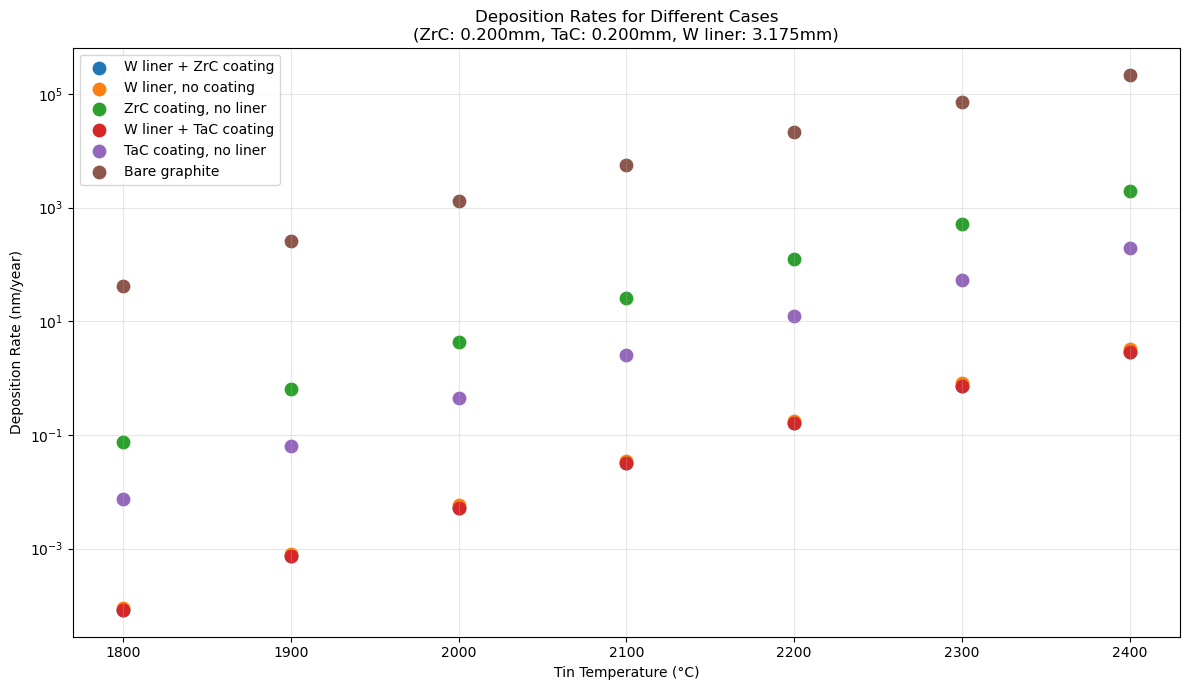

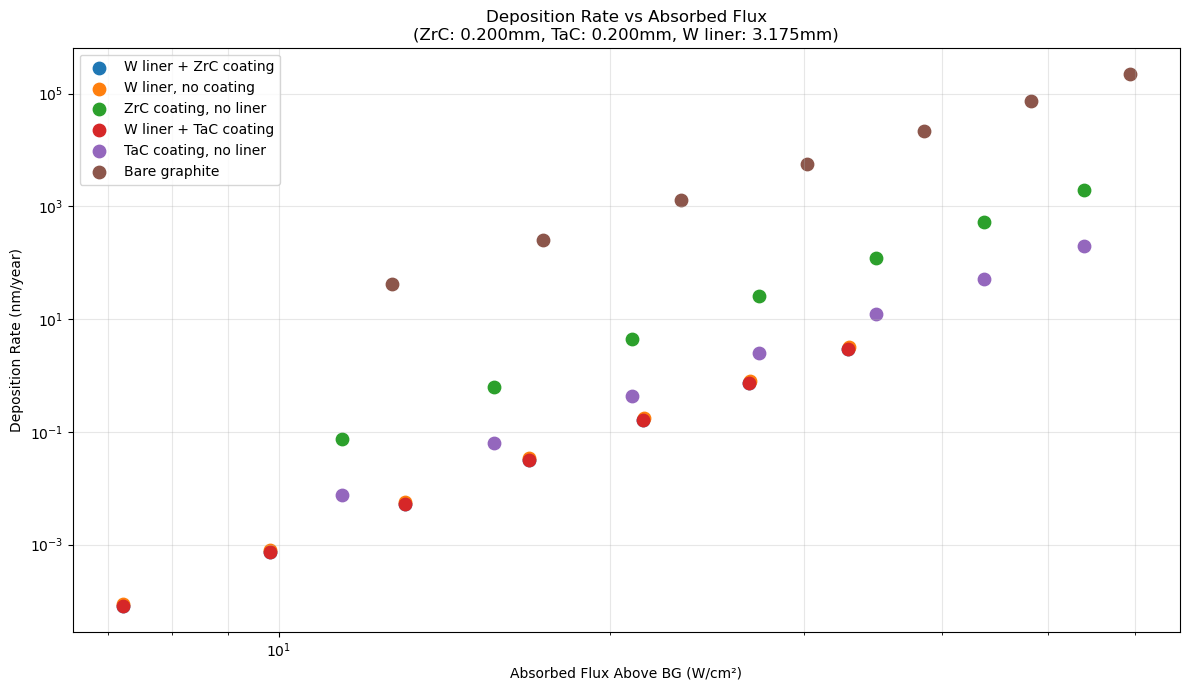

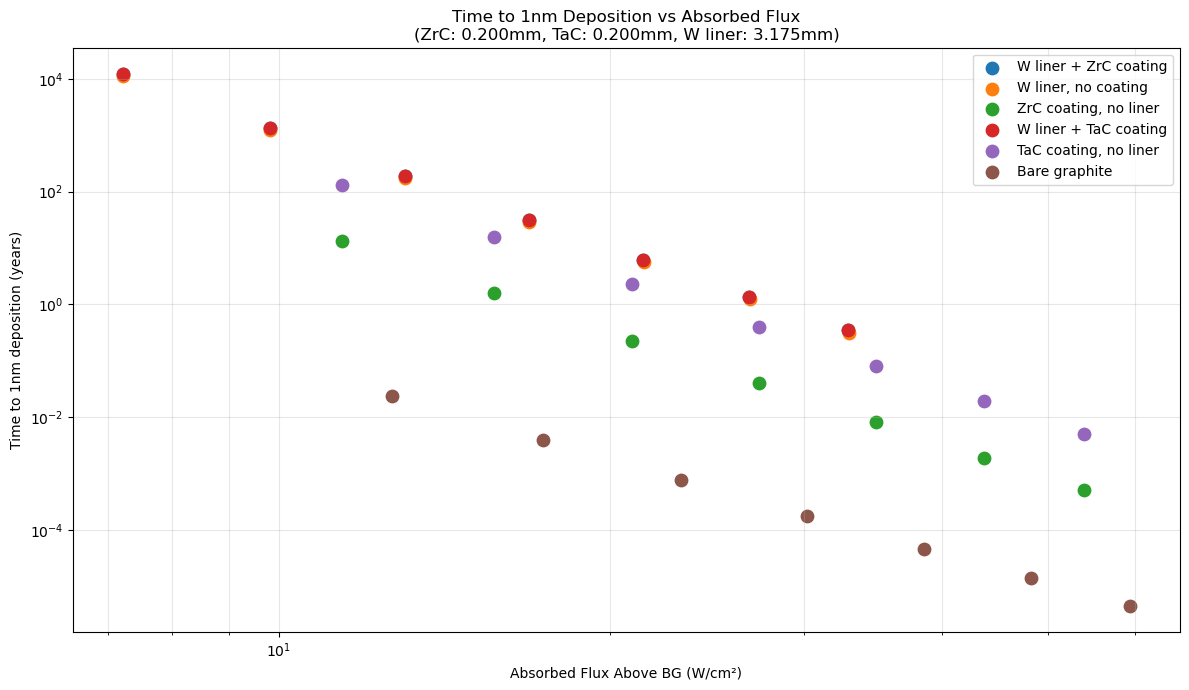

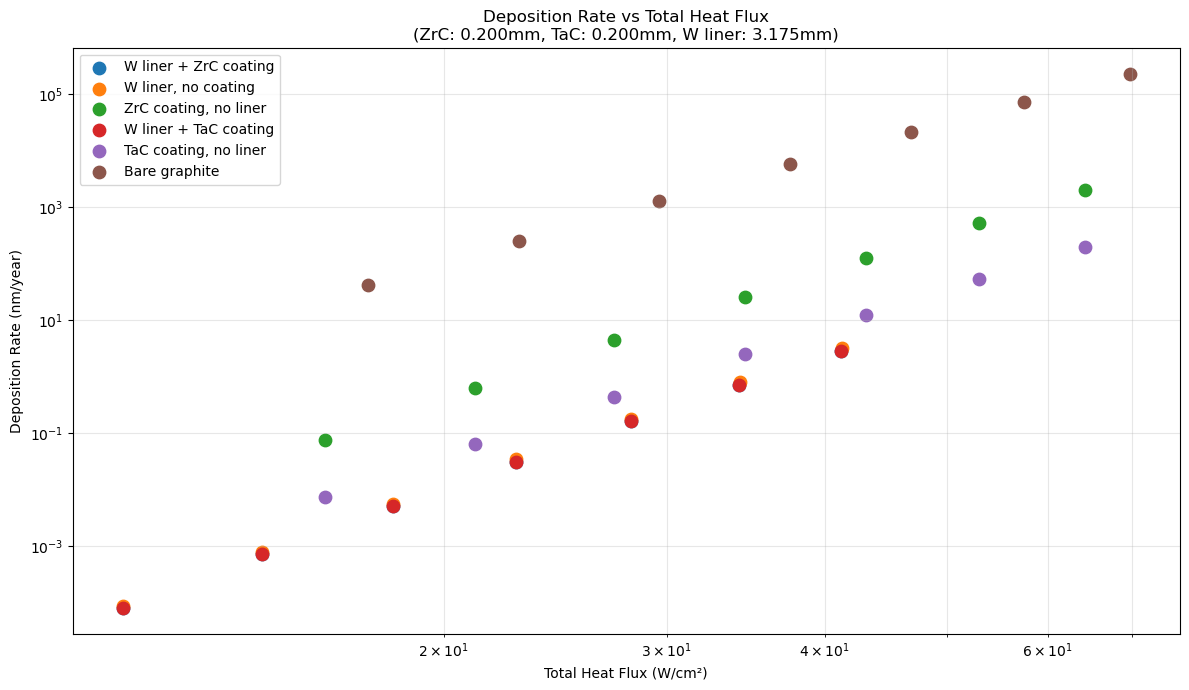

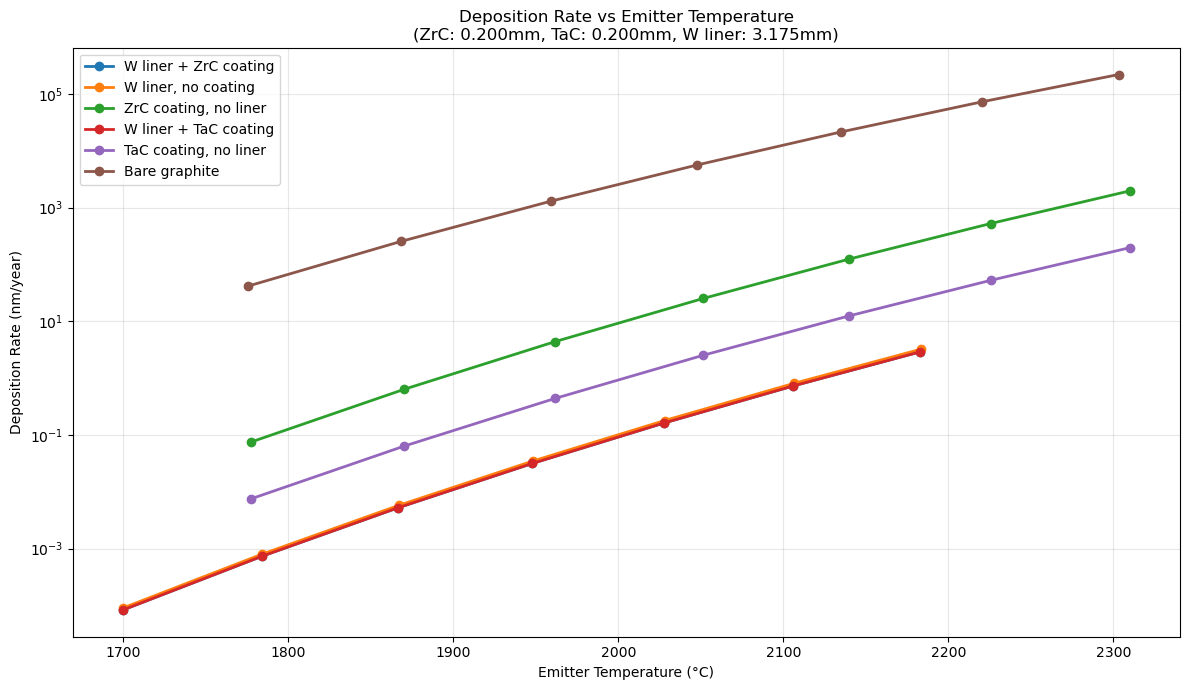

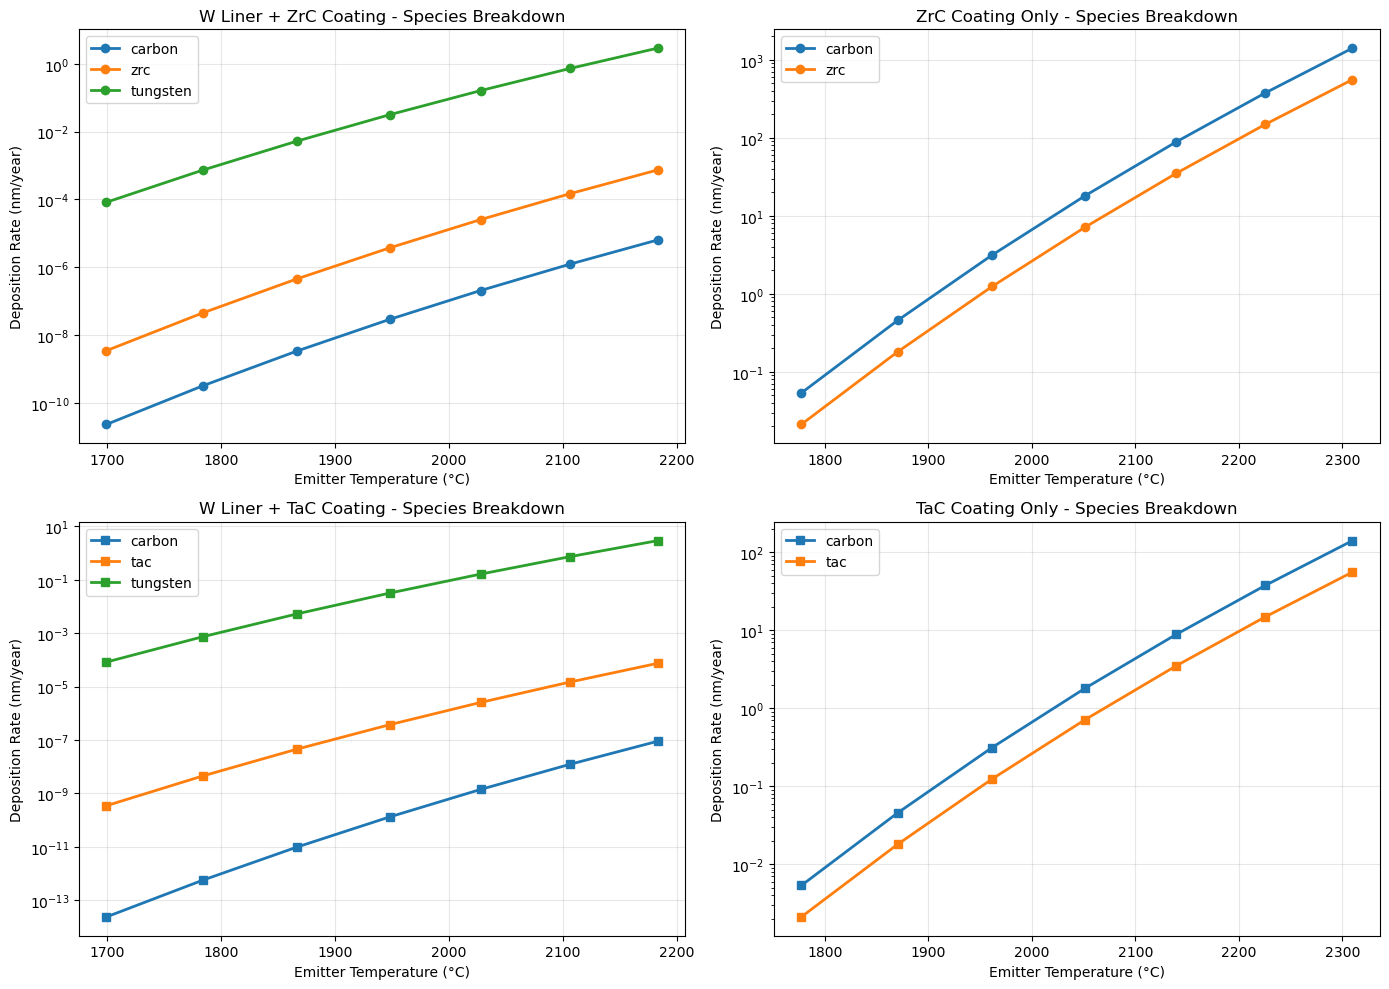

In [96]:
## import matplotlib.pyplot as plt
from scipy.optimize import brentq
emissivity_table = [
        ((0.05, 1.24), 0.95, 0.05, 0.05),  # Below 1 micron
        ((1.24, 25), 0.05, 0.05, 0.05)  # Above 1 micron
    ]

N_cells = 2
diff_or_conv_bool = False #True = diffusion limited, false = convection limited
#T_tin_in = 2673  # K
P_tin_in = 1013250 #Pa
mdot = 35  # kg/s
panel_efficiency = 1
axial_steps = 1
pipe_height = 0.01
emitter_width = 0.3175
length = 3
pipe_roughness=3e-5
powerstick_width = 0.13
crack_width = 100e-6
T_cold = 313.15  # Cold plate temperature in Kelvin
th_gr = 0.0127  # Graphite thickness in meters

# Define coating and liner thicknesses at the top
th_zrc = 200e-6  # ZrC coating thickness in meters (0.2 mm)
th_tac = 200e-6  # TaC coating thickness in meters (0.2 mm)
th_w = 3175e-6   # Tungsten liner thickness in meters (3.175 mm)

f_bare = 0.1
f_active = 0.85
A_cells = 4 * length * powerstick_width * (1-f_bare) * N_cells
geom_vals = [length, emitter_width, powerstick_width, pipe_height, pipe_roughness, P_tin_in, N_cells, mdot, axial_steps, panel_efficiency, f_bare, f_active]
d = (emitter_width - powerstick_width) / 2  # Distance between the coating surface and the cold plate in meters
area_ratio_dep = emitter_width / powerstick_width  # Ratio of emitter area to cold plate area
area_ratio_leak = 0#4 * (2 * emitter_width + length) * crack_width / (4 * emitter_width * length) #ratio of leakage area to liner area
# Plotting the deposition rates for different cases over a range of Tin temperatures
T_tin_range = np.linspace(2073.15, 2673.15, 7)  # Tin range in Kelvin

deposition_rates = {
    "W liner + ZrC coating": [],
    "W liner, no coating": [],
    "ZrC coating, no liner": [],
    "W liner + TaC coating": [],
    "TaC coating, no liner": [],
    "Bare graphite": []
}
emitter_temps = {
    "W liner + ZrC coating": [],
    "W liner, no coating": [],
    "ZrC coating, no liner": [],
    "W liner + TaC coating": [],
    "TaC coating, no liner": [],
    "Bare graphite": []
}
deposition_rates_detail = {
    "W liner + ZrC coating": {"carbon": [], "zrc": [], "tungsten": []},
    "ZrC coating, no liner": {"carbon": [], "zrc": []},
    "W liner + TaC coating": {"carbon": [], "tac": [], "tungsten": []},
    "TaC coating, no liner": {"carbon": [], "tac": []}
}
heat_dep_rates = {
    "W liner + ZrC coating": [],
    "W liner, no coating": [],
    "ZrC coating, no liner": [],
    "W liner + TaC coating": [],
    "TaC coating, no liner": [],
    "Bare graphite": []
}
Q_abs_rates = {
    "W liner + ZrC coating": [],
    "W liner, no coating": [],
    "ZrC coating, no liner": [],
    "W liner + TaC coating": [],
    "TaC coating, no liner": [],
    "Bare graphite": []
}

for T_tin in T_tin_range:
    # Case 1: W liner + ZrC coating
    rate, rate_carbon, rate_zrc, rate_w, _, _, _,T_last, Q_rad, Q_abs = deposition_rate(T_tin, T_cold, th_gr, th_w, th_zrc, d, area_ratio_dep, area_ratio_leak, geom_vals, emissivity_table, diff_or_conv_bool)
    emitter_temps["W liner + ZrC coating"].append(T_last)
    heat_dep_rates["W liner + ZrC coating"].append(Q_rad)
    Q_abs_rates["W liner + ZrC coating"].append(Q_abs)
    deposition_rates["W liner + ZrC coating"].append(rate)
    deposition_rates_detail["W liner + ZrC coating"]["carbon"].append(rate_carbon)
    deposition_rates_detail["W liner + ZrC coating"]["zrc"].append(rate_zrc)
    deposition_rates_detail["W liner + ZrC coating"]["tungsten"].append(rate_w)
    print("W liner + ZrC coating, Tin temp:", T_tin, "rate:", rate, "time:", 8760/rate)

    # Case 2: W liner, no coating
    rate, _, _, _, _, _, _, T_last, Q_rad, Q_abs = deposition_rate(T_tin, T_cold, th_gr, th_w, 0, d, area_ratio_dep, area_ratio_leak, geom_vals, emissivity_table, diff_or_conv_bool)
    heat_dep_rates["W liner, no coating"].append(Q_rad)
    Q_abs_rates["W liner, no coating"].append(Q_abs)
    emitter_temps["W liner, no coating"].append(T_last)
    deposition_rates["W liner, no coating"].append(rate)
    print("W liner, no coating, Tin temp:", T_tin, "rate:", rate, "time:", 8760/rate)
    
    # Case 3: ZrC coating, no liner
    rate, rate_carbon, rate_zrc, _, _, _, _, T_last, Q_rad, Q_abs = deposition_rate(T_tin, T_cold, th_gr, 0, th_zrc, d, area_ratio_dep, area_ratio_leak, geom_vals, emissivity_table, diff_or_conv_bool)
    heat_dep_rates["ZrC coating, no liner"].append(Q_rad)
    Q_abs_rates["ZrC coating, no liner"].append(Q_abs)
    emitter_temps["ZrC coating, no liner"].append(T_last)
    deposition_rates["ZrC coating, no liner"].append(rate)
    deposition_rates_detail["ZrC coating, no liner"]["carbon"].append(rate_carbon)
    deposition_rates_detail["ZrC coating, no liner"]["zrc"].append(rate_zrc)
    print("ZrC coating, no liner, Tin temp:", T_tin, "rate:", rate, "time:", 8760/rate)

    # Case 4: W liner + TaC coating
    rate, rate_carbon, rate_tac, rate_w, _, _, _,T_last, Q_rad, Q_abs = deposition_rate(T_tin, T_cold, th_gr, th_w, th_tac, d, area_ratio_dep, area_ratio_leak, geom_vals, emissivity_table, diff_or_conv_bool, coating_type='TaC')
    emitter_temps["W liner + TaC coating"].append(T_last)
    heat_dep_rates["W liner + TaC coating"].append(Q_rad)
    Q_abs_rates["W liner + TaC coating"].append(Q_abs)
    deposition_rates["W liner + TaC coating"].append(rate)
    deposition_rates_detail["W liner + TaC coating"]["carbon"].append(rate_carbon)
    deposition_rates_detail["W liner + TaC coating"]["tac"].append(rate_tac)
    deposition_rates_detail["W liner + TaC coating"]["tungsten"].append(rate_w)
    print("W liner + TaC coating, Tin temp:", T_tin, "rate:", rate, "time:", 8760/rate)

    # Case 5: TaC coating, no liner
    rate, rate_carbon, rate_tac, _, _, _, _, T_last, Q_rad, Q_abs = deposition_rate(T_tin, T_cold, th_gr, 0, th_tac, d, area_ratio_dep, area_ratio_leak, geom_vals, emissivity_table, diff_or_conv_bool, coating_type='TaC')
    heat_dep_rates["TaC coating, no liner"].append(Q_rad)
    Q_abs_rates["TaC coating, no liner"].append(Q_abs)
    emitter_temps["TaC coating, no liner"].append(T_last)
    deposition_rates["TaC coating, no liner"].append(rate)
    deposition_rates_detail["TaC coating, no liner"]["carbon"].append(rate_carbon)
    deposition_rates_detail["TaC coating, no liner"]["tac"].append(rate_tac)
    print("TaC coating, no liner, Tin temp:", T_tin, "rate:", rate, "time:", 8760/rate)

    # Case 6: Bare graphite (neither)
    rate, _, _, _, _, _, _, T_last, Q_rad, Q_abs = deposition_rate(T_tin, T_cold, th_gr, 0, 0, d, area_ratio_dep, area_ratio_leak, geom_vals, emissivity_table, diff_or_conv_bool)
    heat_dep_rates["Bare graphite"].append(Q_rad)
    Q_abs_rates["Bare graphite"].append(Q_abs)
    emitter_temps["Bare graphite"].append(T_last)
    deposition_rates["Bare graphite"].append(rate)
    print("Bare graphite, Tin temp:", T_tin, "rate:", rate, "time:", 8760/rate)

# Calculate times to accumulate 1 nm of deposition (in years)
times_dict = {}
for label, rates in deposition_rates.items():
    times_dict[label] = np.array([1.0 / rate if rate > 0 else np.inf for rate in rates])

# Store thickness values for dynamic plot titles (in mm for display)
th_w_mm = th_w * 1e3  # Convert to mm
th_zrc_mm = th_zrc * 1e3  # Convert to mm
th_tac_mm = th_tac * 1e3  # Convert to mm

# Plotting the results
plt.figure(figsize=(12, 7))
for label, rates in deposition_rates.items():
    plt.scatter(T_tin_range - 273.15, rates, label=label, s=80)
    
plt.xlabel("Tin Temperature (°C)")
plt.ylabel("Deposition Rate (nm/year)")
plt.yscale('log')
plt.title(f"Deposition Rates for Different Cases\n(ZrC: {th_zrc_mm:.3f}mm, TaC: {th_tac_mm:.3f}mm, W liner: {th_w_mm:.3f}mm)")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 7))
for label, rates in deposition_rates.items():
    Q_rads = np.array(Q_abs_rates[label])
    plt.scatter(Q_rads/A_cells/1e4, rates, label=label, s=80)

plt.xlabel("Absorbed Flux Above BG (W/cm²)")
plt.ylabel("Deposition Rate (nm/year)")
plt.yscale('log')
plt.xscale('log')
plt.title(f"Deposition Rate vs Absorbed Flux\n(ZrC: {th_zrc_mm:.3f}mm, TaC: {th_tac_mm:.3f}mm, W liner: {th_w_mm:.3f}mm)")
plt.legend(loc='best')
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 7))
for label, rates in deposition_rates.items():
    Q_rads = np.array(Q_abs_rates[label])
    times = times_dict[label]
    plt.scatter(Q_rads/A_cells/1e4, times, label=label, s=80)

plt.xlabel("Absorbed Flux Above BG (W/cm²)")
plt.ylabel("Time to 1nm deposition (years)")
plt.yscale('log')
plt.xscale('log')
plt.title(f"Time to 1nm Deposition vs Absorbed Flux\n(ZrC: {th_zrc_mm:.3f}mm, TaC: {th_tac_mm:.3f}mm, W liner: {th_w_mm:.3f}mm)")
plt.legend(loc='best')
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 7))
for label, rates in deposition_rates.items():
    Q_rads = np.array(heat_dep_rates[label])
    plt.scatter(Q_rads/A_cells/1e4, rates, label=label, s=80)

plt.xlabel("Total Heat Flux (W/cm²)")
plt.ylabel("Deposition Rate (nm/year)")
plt.yscale('log')
plt.xscale('log')
plt.title(f"Deposition Rate vs Total Heat Flux\n(ZrC: {th_zrc_mm:.3f}mm, TaC: {th_tac_mm:.3f}mm, W liner: {th_w_mm:.3f}mm)")
plt.legend(loc='best')
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

# Temperature dependence plot
plt.figure(figsize=(12, 7))
for label, rates in deposition_rates.items():
    temps = np.array(emitter_temps[label]) - 273.15
    plt.plot(temps, rates, marker='o', label=label, linewidth=2, markersize=6)

plt.xlabel("Emitter Temperature (°C)")
plt.ylabel("Deposition Rate (nm/year)")
plt.yscale('log')
plt.title(f"Deposition Rate vs Emitter Temperature\n(ZrC: {th_zrc_mm:.3f}mm, TaC: {th_tac_mm:.3f}mm, W liner: {th_w_mm:.3f}mm)")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Detailed species breakdown for coated cases
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ZrC + W liner case
ax = axes[0, 0]
for species, rates in deposition_rates_detail["W liner + ZrC coating"].items():
    temps = np.array(emitter_temps["W liner + ZrC coating"]) - 273.15
    ax.plot(temps, rates, marker='o', label=species, linewidth=2)
ax.set_xlabel("Emitter Temperature (°C)")
ax.set_ylabel("Deposition Rate (nm/year)")
ax.set_yscale('log')
ax.set_title("W Liner + ZrC Coating - Species Breakdown")
ax.legend()
ax.grid(True, alpha=0.3)

# ZrC only case
ax = axes[0, 1]
for species, rates in deposition_rates_detail["ZrC coating, no liner"].items():
    temps = np.array(emitter_temps["ZrC coating, no liner"]) - 273.15
    ax.plot(temps, rates, marker='o', label=species, linewidth=2)
ax.set_xlabel("Emitter Temperature (°C)")
ax.set_ylabel("Deposition Rate (nm/year)")
ax.set_yscale('log')
ax.set_title("ZrC Coating Only - Species Breakdown")
ax.legend()
ax.grid(True, alpha=0.3)

# TaC + W liner case
ax = axes[1, 0]
for species, rates in deposition_rates_detail["W liner + TaC coating"].items():
    temps = np.array(emitter_temps["W liner + TaC coating"]) - 273.15
    ax.plot(temps, rates, marker='s', label=species, linewidth=2)
ax.set_xlabel("Emitter Temperature (°C)")
ax.set_ylabel("Deposition Rate (nm/year)")
ax.set_yscale('log')
ax.set_title("W Liner + TaC Coating - Species Breakdown")
ax.legend()
ax.grid(True, alpha=0.3)

# TaC only case
ax = axes[1, 1]
for species, rates in deposition_rates_detail["TaC coating, no liner"].items():
    temps = np.array(emitter_temps["TaC coating, no liner"]) - 273.15
    ax.plot(temps, rates, marker='s', label=species, linewidth=2)
ax.set_xlabel("Emitter Temperature (°C)")
ax.set_ylabel("Deposition Rate (nm/year)")
ax.set_yscale('log')
ax.set_title("TaC Coating Only - Species Breakdown")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [85]:
# Calculate times to accumulate 1 nm of deposition (in years)
times_dict = {}
for label, rates in deposition_rates.items():
    times_dict[label] = np.array([1.0 / rate if rate > 0 else np.inf for rate in rates])

# D_c = diffusion_coefficient_carbon_tungsten(2150)
th_wc = np.sqrt(D_c * 9.467e7)
print(D_c,th_wc)

SAMPLE COUPON MASS LOSS RATES (25mm x 25mm x 2mm graphite samples)
Coupon dimensions: 25.0mm x 25.0mm x 2.0mm
Surface area (one face): 1250.0 mm^2 = 1.25e-03 m^2
Graphite density: 1743.0 kg/m^3

Temperature: 1800°C (2073K)
--------------------------------------------------------------------------------
  W liner + ZrC coating    :   1.02e-03 nm/yr |   2.53e-07 µg/hr |   2.22e-09 g/yr |   2.22e-12 kg/yr
  W liner, no coating      :   1.03e-03 nm/yr |   2.56e-07 µg/hr |   2.24e-09 g/yr |   2.24e-12 kg/yr
  ZrC coating, no liner    :   8.30e-01 nm/yr |   2.06e-04 µg/hr |   1.81e-06 g/yr |   1.81e-09 kg/yr
  W liner + TaC coating    :   1.02e-03 nm/yr |   2.53e-07 µg/hr |   2.22e-09 g/yr |   2.22e-12 kg/yr
  TaC coating, no liner    :   8.30e-02 nm/yr |   2.06e-05 µg/hr |   1.81e-07 g/yr |   1.81e-10 kg/yr
  Bare graphite            :   4.43e+02 nm/yr |   1.10e-01 µg/hr |   9.66e-04 g/yr |   9.66e-07 kg/yr

Temperature: 1900°C (2173K)
-------------------------------------------------------

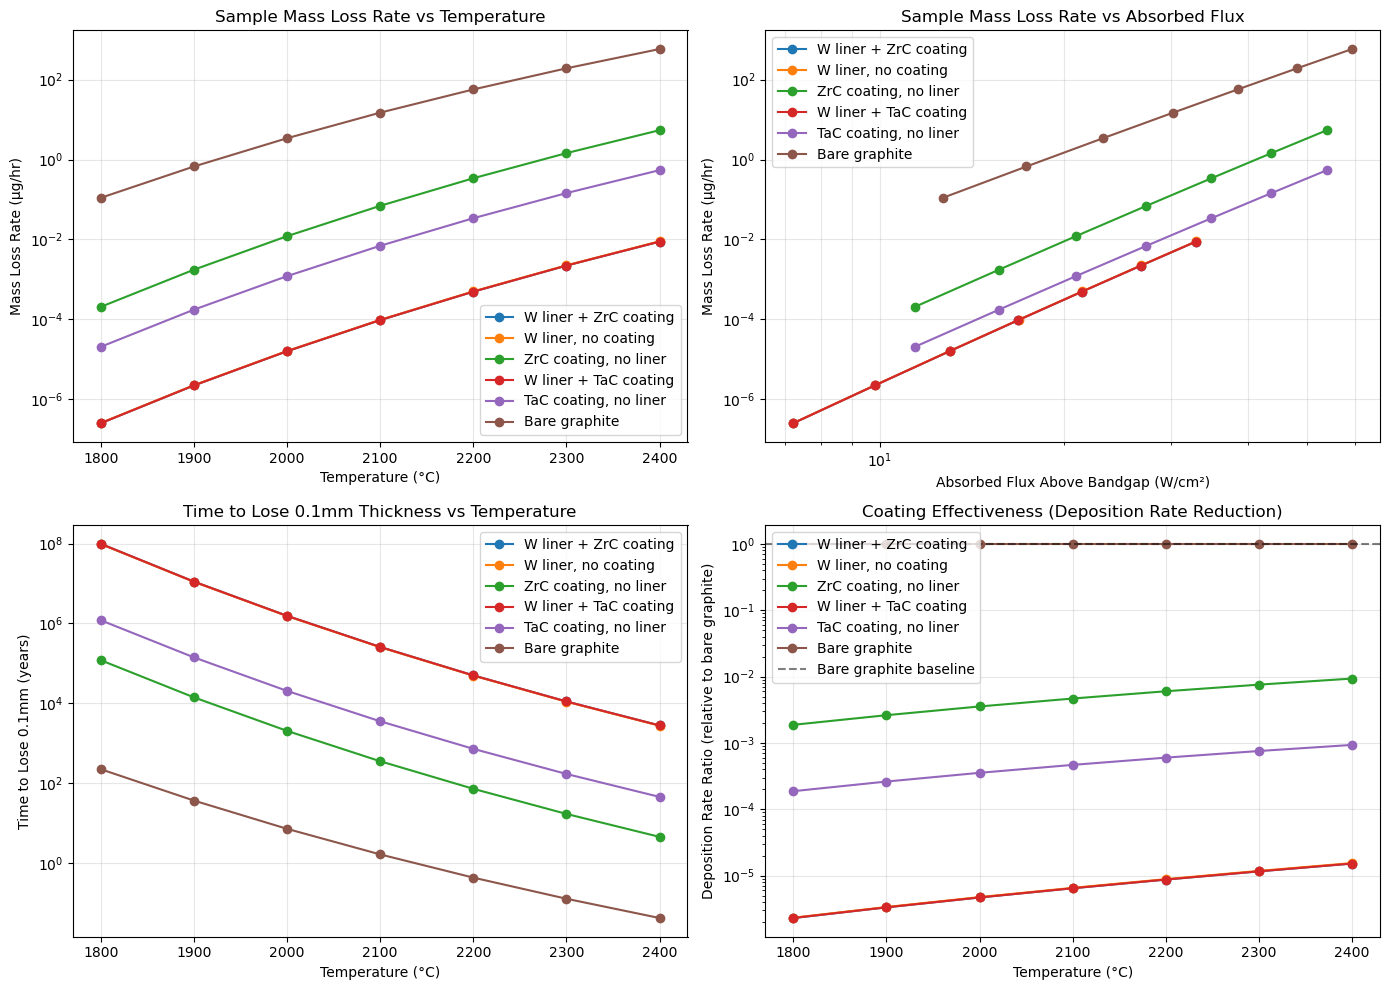


SUMMARY: Mass Loss Reduction by Coatings
W liner + ZrC coating    : Average 195902.7x reduction in deposition rate
W liner, no coating      : Average 193544.2x reduction in deposition rate
ZrC coating, no liner    : Average 259.9x reduction in deposition rate
W liner + TaC coating    : Average 195904.2x reduction in deposition rate
TaC coating, no liner    : Average 2599.3x reduction in deposition rate

TAC COATING SAMPLE ANALYSIS (25mm x 25mm x 2mm TaC samples)
TaC density: 14500.0 kg/m³
Sample surface area: 1.25e-03 m²

Temperature: 1800°C (2073K)
--------------------------------------------------------------------------------
  W liner + TaC coating    :   4.03e-10 nm/yr |   8.33e-13 µg/hr |   7.30e-15 g/yr |   7.30e-18 kg/yr
  TaC coating, no liner    :   2.61e-02 nm/yr |   5.39e-05 µg/hr |   4.72e-07 g/yr |   4.72e-10 kg/yr

Temperature: 1900°C (2173K)
--------------------------------------------------------------------------------
  W liner + TaC coating    :   5.19e-09 nm/yr | 

In [86]:
# Sample coupon specifications
coupon_length = 25e-3  # 25 mm in meters
coupon_width = 25e-3   # 25 mm in meters
coupon_thickness = 2e-3  # 2 mm in meters

# Surface area (assuming we're interested in the two 25x25 mm faces)
A_coupon = 2 * coupon_length * coupon_width  # m^2

# Material densities
rho_graphite = gr_rho(T_cold)  # kg/m^3
rho_zrc = 6530  # kg/m^3 (approximate density of ZrC)
rho_tac = 14500  # kg/m^3 (approximate density of TaC)

# Calculate mass loss rates in kg/year for each case
# Deposition rate is in nm/year, which translates to volume loss per unit area per year
mass_loss_rates = {}

for label, dep_rates in deposition_rates.items():
    # Convert deposition rates from nm/year to meters/year
    dep_rates_m_yr = np.array(dep_rates) * 1e-9
    
    # Volume loss per year: (depth in m/yr) * (area in m^2) = m^3/yr
    volume_loss_m3_yr = dep_rates_m_yr * A_coupon
    
    # Mass loss per year: volume * density
    mass_loss_kg_yr = volume_loss_m3_yr * rho_graphite
    
    # Convert to grams per year for easier interpretation
    mass_loss_g_yr = mass_loss_kg_yr * 1000
    
    # Convert to micrograms per hour
    # 1 g/yr = 1e6 µg/yr = 1e6 µg / (365.25 * 24 hr) = 114.08 µg/hr
    hours_per_year = 365.25 * 24
    mass_loss_ug_hr = mass_loss_g_yr * 1e6 / hours_per_year
    
    mass_loss_rates[label] = {
        'kg/yr': mass_loss_kg_yr,
        'g/yr': mass_loss_g_yr,
        'µg/hr': mass_loss_ug_hr
    }

# Display results
print("=" * 80)
print("SAMPLE COUPON MASS LOSS RATES (25mm x 25mm x 2mm graphite samples)")
print("=" * 80)
print(f"Coupon dimensions: {coupon_length*1e3:.1f}mm x {coupon_width*1e3:.1f}mm x {coupon_thickness*1e3:.1f}mm")
print(f"Surface area (one face): {A_coupon*1e6:.1f} mm^2 = {A_coupon:.2e} m^2")
print(f"Graphite density: {rho_graphite:.1f} kg/m^3")
print("=" * 80)

for i, T_tin in enumerate(T_tin_range):
    print(f"\nTemperature: {T_tin - 273.15:.0f}°C ({T_tin:.0f}K)")
    print("-" * 80)
    for label in deposition_rates.keys():
        dep_rate_nm_yr = deposition_rates[label][i]
        mass_loss_g = mass_loss_rates[label]['g/yr'][i]
        mass_loss_kg = mass_loss_rates[label]['kg/yr'][i]
        mass_loss_ug = mass_loss_rates[label]['µg/hr'][i]
        time_for_1nm = times_dict[label][i]
        
        print(f"  {label:25s}: {dep_rate_nm_yr:10.2e} nm/yr | {mass_loss_ug:10.2e} µg/hr | "
              f"{mass_loss_g:10.2e} g/yr | {mass_loss_kg:10.2e} kg/yr")

# Create comparison plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Mass loss rates vs temperature (in µg/hr)
ax = axes[0, 0]
for label in deposition_rates.keys():
    mass_loss = mass_loss_rates[label]['µg/hr']
    ax.semilogy(T_tin_range - 273.15, mass_loss, marker='o', label=label)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Mass Loss Rate (µg/hr)")
ax.set_title("Sample Mass Loss Rate vs Temperature")
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Mass loss rates vs absorbed flux (in µg/hr)
ax = axes[0, 1]
for label in deposition_rates.keys():
    Q_rads = np.array(Q_abs_rates[label])
    mass_loss = mass_loss_rates[label]['µg/hr']
    ax.loglog(Q_rads/A_cells/1e4, mass_loss, marker='o', label=label)
ax.set_xlabel("Absorbed Flux Above Bandgap (W/cm²)")
ax.set_ylabel("Mass Loss Rate (µg/hr)")
ax.set_title("Sample Mass Loss Rate vs Absorbed Flux")
ax.legend()
ax.grid(True, alpha=0.3, which='both')

# Plot 3: Time to lose 0.1mm thickness
ax = axes[1, 0]
time_to_loss = {}
for label in deposition_rates.keys():
    # Depth of 0.1 mm = 100,000 nm
    depth_nm = 0.1e-3 * 1e9  # 0.1 mm in nm
    time_years = depth_nm / np.array(deposition_rates[label])
    time_to_loss[label] = time_years
    ax.semilogy(T_tin_range - 273.15, time_years, marker='o', label=label)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Time to Lose 0.1mm (years)")
ax.set_title("Time to Lose 0.1mm Thickness vs Temperature")
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Comparison of coated vs uncoated (normalized)
ax = axes[1, 1]
bare_rate = np.array(deposition_rates['Bare graphite'])
for label in deposition_rates.keys():
    rate_ratio = np.array(deposition_rates[label]) / bare_rate
    ax.semilogy(T_tin_range - 273.15, rate_ratio, marker='o', label=label)
ax.axhline(y=1, color='k', linestyle='--', alpha=0.5, label='Bare graphite baseline')
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Deposition Rate Ratio (relative to bare graphite)")
ax.set_title("Coating Effectiveness (Deposition Rate Reduction)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print("\n" + "=" * 80)
print("SUMMARY: Mass Loss Reduction by Coatings")
print("=" * 80)
bare_rates = np.array(deposition_rates['Bare graphite'])
for label in deposition_rates.keys():
    if label != 'Bare graphite':
        coated_rates = np.array(deposition_rates[label])
        reduction_factor = bare_rates / coated_rates
        avg_reduction = np.mean(reduction_factor)
        print(f"{label:25s}: Average {avg_reduction:.1f}x reduction in deposition rate")

# Analysis of TaC coating sample mass loss
print("\n" + "=" * 80)
print("TAC COATING SAMPLE ANALYSIS (25mm x 25mm x 2mm TaC samples)")
print("=" * 80)
print(f"TaC density: {rho_tac:.1f} kg/m³")
print(f"Sample surface area: {A_coupon:.2e} m²")
print("=" * 80)

tac_sample_loss_rates = {}
# For TaC samples, we track the TaC deposition rate (coating material that deposits on the TaC sample)
for label in deposition_rates.keys():
    if 'TaC' in label:
        dep_rates_m_yr = np.array(deposition_rates_detail[label]['tac']) * 1e-9
        volume_loss_m3_yr = dep_rates_m_yr * A_coupon
        mass_loss_kg_yr = volume_loss_m3_yr * rho_tac
        mass_loss_g_yr = mass_loss_kg_yr * 1000
        hours_per_year = 365.25 * 24
        mass_loss_ug_hr = mass_loss_g_yr * 1e6 / hours_per_year
        
        tac_sample_loss_rates[label] = {
            'kg/yr': mass_loss_kg_yr,
            'g/yr': mass_loss_g_yr,
            'µg/hr': mass_loss_ug_hr
        }

for i, T_tin in enumerate(T_tin_range):
    print(f"\nTemperature: {T_tin - 273.15:.0f}°C ({T_tin:.0f}K)")
    print("-" * 80)
    for label in tac_sample_loss_rates.keys():
        mass_loss_g = tac_sample_loss_rates[label]['g/yr'][i]
        mass_loss_kg = tac_sample_loss_rates[label]['kg/yr'][i]
        mass_loss_ug = tac_sample_loss_rates[label]['µg/hr'][i]
        tac_dep_rate = deposition_rates_detail[label]['tac'][i]
        
        print(f"  {label:25s}: {tac_dep_rate:10.2e} nm/yr | {mass_loss_ug:10.2e} µg/hr | "
              f"{mass_loss_g:10.2e} g/yr | {mass_loss_kg:10.2e} kg/yr")


In [ ]:
rate= 1e5
T_ar = 2573
V_cavity = length * (emitter_width **2 - powerstick_width **2)
molar_rate = rate/(1e9*365*86400) * A_cells * gr_rho_molar(T_ar)S
dPdt = molar_rate*8.314*T_ar/V_cavity
print(dPdt)

0.041418061692916446


In [100]:
vapor_pressure_tac(2250)

7.743215991760639e-08